In [1]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3


In [4]:
# download dataset

from pathlib import Path
from google.colab import userdata
from roboflow import Roboflow

project_folder = Path("/content/ODOL")

raw_dataset_folder = project_folder / "dataset" / "raw"
source_dataset = raw_dataset_folder / "truck-over-dimension"
results_folder = project_folder / "results"

raw_dataset_folder.mkdir(parents=True, exist_ok=True)
results_folder.mkdir(parents=True, exist_ok=True)

ROBOFLOW_API_KEY = userdata.get("ROBOFLOW_API_KEY")
roboflow = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = roboflow.workspace("sigara-hpnoo")
dataset_project = workspace.project("truck-over-dimension-brupr")
dataset_version = dataset_project.version(2)

dataset = dataset_version.download(
    "yolov8",
    location=str(source_dataset)
)

source_dataset = Path(dataset.location)

source_dataset

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/ODOL/dataset/raw/truck-over-dimension in yolov8:: 100%|██████████| 5718/5718 [00:02<00:00, 2756.76it/s]


PosixPath('/content/ODOL/dataset/raw/truck-over-dimension')

In [5]:
# read class names

import yaml

data_yaml = source_dataset / "data.yaml"

dataset_information = yaml.safe_load(
    data_yaml.read_text()
)

class_names = dataset_information["names"]

class_names

['NOT ODOL', 'ODOL']

In [6]:
# collect images and labels

image_label_pairs = []

for split_name in ["train", "valid", "test"]:
    image_folder = source_dataset / split_name / "images"
    label_folder = source_dataset / split_name / "labels"

    for image_file in sorted(image_folder.glob("*.jpg")):
        label_file = label_folder / f"{image_file.stem}.txt"

        image_label_pairs.append(
            (split_name, image_file, label_file)
        )

len(image_label_pairs)

2853

In [7]:
# group augmented copies

image_groups = {}

for split_name, image_file, label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]

    if original_name not in image_groups:
        image_groups[original_name] = []

    image_groups[original_name].append(
        (split_name, image_file, label_file)
    )

len(image_groups)

1095

In [8]:
# check groups across existing splits

groups_in_multiple_splits = 0

for group_items in image_groups.values():
    split_names = set()

    for split_name, image_file, label_file in group_items:
        split_names.add(split_name)

    if len(split_names) > 1:
        groups_in_multiple_splits += 1

print("Groups in multiple splits:", groups_in_multiple_splits)

Groups in multiple splits: 0


In [9]:
# identify groups containing ODOL

group_names = sorted(image_groups.keys())
group_labels = []

for group_name in group_names:
    contains_odol = False

    for split_name, image_file, label_file in image_groups[group_name]:
        label_lines = label_file.read_text().splitlines()

        for label_line in label_lines:
            label_values = label_line.split()
            class_id = int(label_values[0])

            if class_id == 1:
                contains_odol = True
                break

        if contains_odol:
            break

    if contains_odol:
        group_labels.append(1)
    else:
        group_labels.append(0)

print("Total groups:", len(group_names))

Total groups: 1095


In [10]:
# split groups into training, validation, and test

from sklearn.model_selection import train_test_split

train_groups, remaining_groups, train_labels, remaining_labels = (
    train_test_split(
        group_names,
        group_labels,
        test_size=0.30,
        stratify=group_labels,
        random_state=42
    )
)

valid_groups, test_groups = train_test_split(
    remaining_groups,
    test_size=0.50,
    stratify=remaining_labels,
    random_state=42
)

print("Train groups:", len(train_groups))
print("Validation groups:", len(valid_groups))
print("Test groups:", len(test_groups))

Train groups: 766
Validation groups: 164
Test groups: 165


In [11]:
# assign each group its new split

split_groups = {
    "train": train_groups,
    "valid": valid_groups,
    "test": test_groups
}

group_to_new_split = {}

for split_name, groups in split_groups.items():
    for group_name in groups:
        group_to_new_split[group_name] = split_name

print("Assigned groups:", len(group_to_new_split))

Assigned groups: 1095


In [12]:
# inspect one label file

split_name, image_file, label_file = image_label_pairs[0]

print("Image:", image_file.name)
print("Label:", label_file.name)
print("Annotations:")
print(label_file.read_text())

Image: 02022020-hil-bisnis-21-truk-odol_5_jpg.rf.36ca0f4b40f6d50e75911859e782e37f.jpg
Label: 02022020-hil-bisnis-21-truk-odol_5_jpg.rf.36ca0f4b40f6d50e75911859e782e37f.txt
Annotations:
1 0.770855090625 1 0.7769230765625 0.9827849000000001 0.784615384375 0.8156837609375 0.79076923125 0.43600284843750003 0.7769230765625 0.3827849 0.7184615390625 0.2997535609375 0.684615384375 0.28299857500000003 0.5538461531250001 0.27371794843749997 0.466153846875 0.276670940625 0.4523076921875 0.2884529921875 0.455384615625 0.6336125359375 0.48 0.7123888890625001 0.49230769218750003 0.890527065625 0.5323076921875 0.9326011390625 0.5422426734375 1 0.770855090625 1
1 0.45846153906250003 0.041272079687500005 0.3476923078125 0.045528490625 0.33999999999999997 0.0551296296875 0.3369230765625 0.0849700859375 0.3369230765625 0.19997008593750001 0.36307692343750003 0.4638262109375 0.3769230765625 0.48454415937500006 0.3815384609375 0.514783475 0.45076923124999996 0.52087321875 0.4569230765625 0.5061923078125 0

In [13]:
# prepare crop dataset folder

import cv2
import shutil

crop_dataset = project_folder / "dataset" / "mobilenet"

shutil.rmtree(crop_dataset, ignore_errors=True)

crop_dataset


PosixPath('/content/ODOL/dataset/mobilenet')

In [14]:
# crop trucks into class folders

for split_name, image_file, label_file in image_label_pairs:
    original_name = image_file.stem.split(".rf.")[0]
    split_name = group_to_new_split[original_name]

    image = cv2.imread(str(image_file))
    image_height, image_width = image.shape[:2]

    label_lines = label_file.read_text().splitlines()

    for crop_number, label_line in enumerate(label_lines):
        label_values = label_line.split()
        class_id = int(label_values[0])

        # convert annotation coordinates into numbers

        coordinates = []

        for value in label_values[1:]:
            coordinates.append(float(value))

        # find crop boundaries from a bounding box

        if len(coordinates) == 4:
            center_x, center_y, box_width, box_height = coordinates

            left = int((center_x - box_width / 2) * image_width)
            top = int((center_y - box_height / 2) * image_height)
            right = int((center_x + box_width / 2) * image_width)
            bottom = int((center_y + box_height / 2) * image_height)

        # find crop boundaries from a polygon

        else:
            x_coordinates = []
            y_coordinates = []

            for coordinate_index in range(0, len(coordinates), 2):
                x_coordinates.append(coordinates[coordinate_index])
                y_coordinates.append(coordinates[coordinate_index + 1])

            left = int(min(x_coordinates) * image_width)
            top = int(min(y_coordinates) * image_height)
            right = int(max(x_coordinates) * image_width)
            bottom = int(max(y_coordinates) * image_height)

        # keep crop boundaries inside the image

        left = max(0, min(left, image_width))
        top = max(0, min(top, image_height))
        right = max(0, min(right, image_width))
        bottom = max(0, min(bottom, image_height))

        # prepare the destination class folder

        class_name = class_names[class_id]
        class_folder_name = class_name.replace(" ", "_")

        class_folder = crop_dataset / split_name / class_folder_name
        class_folder.mkdir(parents=True, exist_ok=True)

        # crop and save the truck image

        crop = image[top:bottom, left:right]
        crop_filename = f"{image_file.stem}_{crop_number}.jpg"
        crop_path = class_folder / crop_filename

        cv2.imwrite(str(crop_path), crop)

crop_dataset

PosixPath('/content/ODOL/dataset/mobilenet')

In [15]:
# count crops in each split

for split_name in ["train", "valid", "test"]:
    print("Split:", split_name)

    for class_name in class_names:
        class_folder_name = class_name.replace(" ", "_")
        class_folder = crop_dataset / split_name / class_folder_name

        crop_files = list(class_folder.glob("*.jpg"))
        crop_count = len(crop_files)

        print(class_name + ":", crop_count)

    print()

Split: train
NOT ODOL: 884
ODOL: 710

Split: valid
NOT ODOL: 211
ODOL: 160

Split: test
NOT ODOL: 184
ODOL: 155



In [16]:
# prepare image preprocessing and augmentation

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_data = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=8,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    brightness_range=[0.85, 1.15],
    horizontal_flip=True
)

valid_data = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_data = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


In [17]:
# load crops from folders

train_generator = train_data.flow_from_directory(
    crop_dataset / "train",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=True,
    seed=42
)

valid_generator = valid_data.flow_from_directory(
    crop_dataset / "valid",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

test_generator = test_data.flow_from_directory(
    crop_dataset / "test",
    target_size=(224, 224),
    batch_size=32,
    class_mode="binary",
    shuffle=False
)

print("Class labels:", train_generator.class_indices)


Found 1594 images belonging to 2 classes.
Found 371 images belonging to 2 classes.
Found 339 images belonging to 2 classes.
Class labels: {'NOT_ODOL': 0, 'ODOL': 1}


In [18]:
# build MobileNetV2 classifier

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

pooled_features = GlobalAveragePooling2D()(base_model.output)

odol_probability = Dense(
    1,
    activation="sigmoid"
)(pooled_features)

model = Model(
    inputs=base_model.input,
    outputs=odol_probability
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
# configure initial training

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [20]:
# prepare initial training callbacks

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

final_model_path = (
    results_folder
    / "mobilenet_odol_classifier.keras"
)

training_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=15,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=final_model_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [21]:
# train classifier with MobileNetV2 frozen

history = model.fit(
    train_generator,
    epochs=100,
    validation_data=valid_generator,
    callbacks=training_callbacks
)

Epoch 1/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 52s 799ms/step - accuracy: 0.6738 - loss: 0.6085 - val_accuracy: 0.6981 - val_loss: 0.5782
Epoch 2/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 550ms/step - accuracy: 0.7829 - loss: 0.4844 - val_accuracy: 0.7332 - val_loss: 0.5092
Epoch 3/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 558ms/step - accuracy: 0.8237 - loss: 0.4156 - val_accuracy: 0.7898 - val_loss: 0.4712
Epoch 4/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 531ms/step - accuracy: 0.8576 - loss: 0.3681 - val_accuracy: 0.8113 - val_loss: 0.4442
Epoch 5/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 537ms/step - accuracy: 0.8532 - loss: 0.3459 - val_accuracy: 0.8221 - val_loss: 0.4334
Epoch 6/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 540ms/step - accuracy: 0.8752 - loss: 0.3213 - val_accuracy: 0.8356 - val_loss: 0.4129
Epoch 7/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 519ms/step - accuracy: 0.8777 - loss: 0.3117 - val_accuracy: 0.8518 - val_loss: 0.3948
Epoch 8/100
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 522ms/step - accuracy: 0.8902 - loss: 0.2921 - 

In [22]:
# configure fine-tuning

base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

fine_tuning_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=10,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=final_model_path,
        monitor="val_accuracy",
        save_best_only=True
    )
]

In [23]:
# fine-tune model

history2 = model.fit(
    train_generator,
    epochs=30,
    validation_data=valid_generator,
    callbacks=fine_tuning_callbacks
)

Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 55s 787ms/step - accuracy: 0.7597 - loss: 0.5241 - val_accuracy: 0.8167 - val_loss: 0.4208
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 505ms/step - accuracy: 0.8381 - loss: 0.3552 - val_accuracy: 0.7951 - val_loss: 0.4532
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 531ms/step - accuracy: 0.8701 - loss: 0.3103 - val_accuracy: 0.8005 - val_loss: 0.4329
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 511ms/step - accuracy: 0.8890 - loss: 0.2561 - val_accuracy: 0.8437 - val_loss: 0.3853
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 516ms/step - accuracy: 0.9028 - loss: 0.2363 - val_accuracy: 0.8706 - val_loss: 0.3639
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 518ms/step - accuracy: 0.9228 - loss: 0.2158 - val_accuracy: 0.8787 - val_loss: 0.3554
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 26s 521ms/step - accuracy: 0.9115 - loss: 0.2122 - val_accuracy: 0.8733 - val_loss: 0.3518
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 25s 502ms/step - accuracy: 0.9235 - loss: 0.2017 - val_accu

In [24]:
# predict classes for test crops

test_generator.reset()

predictions = model.predict(test_generator)

y_true = test_generator.classes
y_pred = []

for prediction in predictions:
    odol_probability = prediction[0]

    if odol_probability > 0.5:
        y_pred.append(1)
    else:
        y_pred.append(0)

11/11 ━━━━━━━━━━━━━━━━━━━━ 8s 422ms/step


In [25]:
# calculate and show test results

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

matrix = confusion_matrix(y_true, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 score:", round(f1, 4))

print()
print("Confusion matrix:")
print(matrix)


Accuracy: 0.9263
Precision: 0.9062
Recall: 0.9355
F1 score: 0.9206

Confusion matrix:
[[169  15]
 [ 10 145]]


In [26]:
# combine initial training and fine-tuning histories

training_accuracy = (
    history.history["accuracy"]
    + history2.history["accuracy"]
)

validation_accuracy = (
    history.history["val_accuracy"]
    + history2.history["val_accuracy"]
)

training_loss = (
    history.history["loss"]
    + history2.history["loss"]
)

validation_loss = (
    history.history["val_loss"]
    + history2.history["val_loss"]
)

epoch_numbers = range(1, len(training_accuracy) + 1)

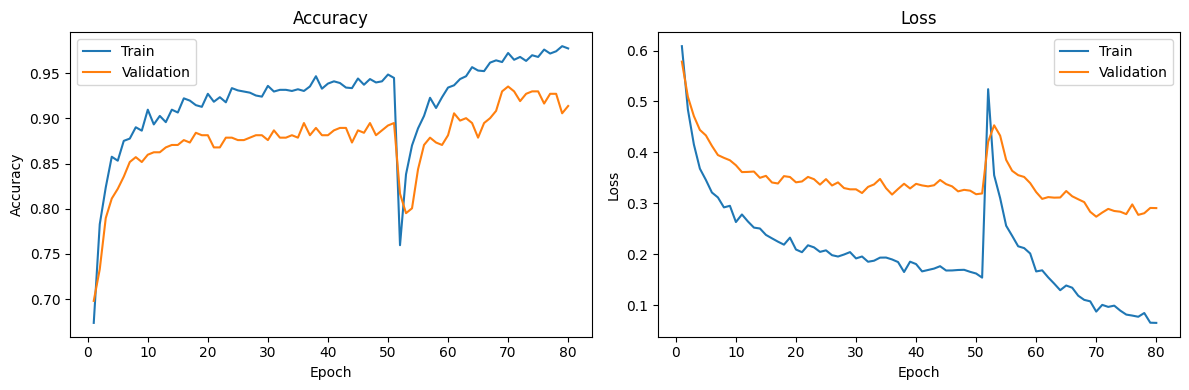

In [27]:
# show training progress

import matplotlib.pyplot as plt

training_plot_path = (
    results_folder
    / "mobilenet_training_history.png"
)

plt.figure(figsize=(12, 4))

# show accuracy

plt.subplot(1, 2, 1)

plt.plot(epoch_numbers, training_accuracy, label="Train")
plt.plot(epoch_numbers, validation_accuracy, label="Validation")

plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# show loss

plt.subplot(1, 2, 2)

plt.plot(epoch_numbers, training_loss, label="Train")
plt.plot(epoch_numbers, validation_loss, label="Validation")

plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(training_plot_path)
plt.show()


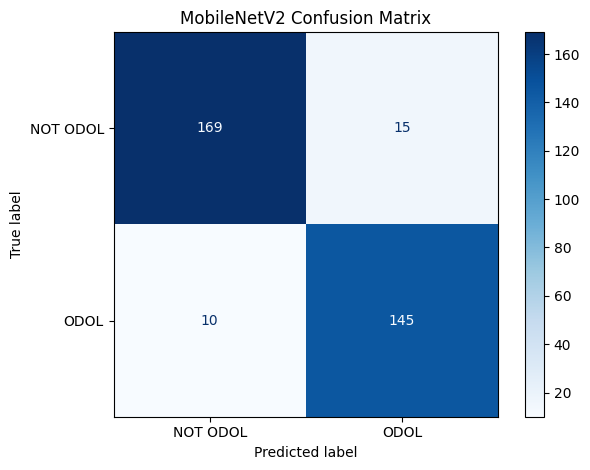

In [28]:
# show test confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

confusion_matrix_path = (
    results_folder
    / "mobilenet_confusion_matrix.png"
)

confusion_matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
)

confusion_matrix_display.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.savefig(confusion_matrix_path)
plt.show()


In [29]:
# show classification report

from sklearn.metrics import classification_report

test_report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
)

print(test_report)


              precision    recall  f1-score   support

    NOT ODOL       0.94      0.92      0.93       184
        ODOL       0.91      0.94      0.92       155

    accuracy                           0.93       339
   macro avg       0.93      0.93      0.93       339
weighted avg       0.93      0.93      0.93       339



In [30]:
# save evaluated model

model.save(final_model_path)

final_model_path

PosixPath('/content/ODOL/results/mobilenet_odol_classifier.keras')

In [31]:
# reload saved model

from tensorflow.keras.models import load_model

classifier_model = load_model(final_model_path)

classifier_model

<Functional name=functional, built=True>

In [32]:
# download saved model

from google.colab import files

files.download(str(final_model_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>